# Semantic segmentation — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/segmentation/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("segmentation", cfg)
print("task:", "segmentation", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: segmentation | data: data/demo/segmentation | outputs: outputs/segmentation_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/segmentation
  images_dir: images
  masks_dir: masks
  classes_file: classes.txt
  ignore_index: 255
  image_size: 128
  batch_size: 16
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    hflip: true
    vflip: true
    rotation: 0
    color_jitter: 0.0
model:
  arch: unet_resnet18
  pretrained: false
train:
  epochs: 40
  lr: 0.002
  weight_decay: 0.0001
  dice_weight: 0.5
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
import torch
from cvkit.utils import count_parameters
from tasks.segmentation.data import build_loaders
from tasks.segmentation.model import build_model

classes = build_loaders(cfg)["classes"]
model = build_model(cfg, {"classes": classes})
p = count_parameters(model)
size = cfg["data"]["image_size"]
out = model.eval()(torch.randn(1, 3, size, size))
print(f"arch {cfg['model']['arch']} | pretrained {cfg['model']['pretrained']} | {len(classes)} classes")
print(f"{p['total']:,} parameters, {p['trainable']:,} trainable | input (1,3,{size},{size}) -> output {tuple(out.shape)}: a score per class per pixel")
del model

arch unet_resnet18 | pretrained False | 4 classes
14,321,220 parameters, 14,321,220 trainable | input (1,3,128,128) -> output (1, 4, 128, 128): a score per class per pixel


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.segmentation.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: unet_resnet18 | classes (4): ['background', 'circle', 'square', 'triangle']
device: cpu | parameters: 14,321,220 total, 14,321,220 trainable (100.0%)


epoch   1/40 | train_loss 1.2295 | val miou=0.223 mdice=0.236 pixel_acc=0.894 | 6.8s  <- best


epoch   2/40 | train_loss 0.8138 | val miou=0.352 mdice=0.396 pixel_acc=0.935 | 6.8s  <- best


epoch   3/40 | train_loss 0.6185 | val miou=0.352 mdice=0.398 pixel_acc=0.935 | 6.8s  <- best


epoch   4/40 | train_loss 0.5045 | val miou=0.382 mdice=0.447 pixel_acc=0.937 | 6.4s  <- best


...

epoch  36/40 | train_loss 0.0610 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.4s  <- best


epoch  37/40 | train_loss 0.0604 | val miou=0.910 mdice=0.952 pixel_acc=0.993 | 6.5s


epoch  38/40 | train_loss 0.0641 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.6s


epoch  39/40 | train_loss 0.0580 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.4s


epoch  40/40 | train_loss 0.0622 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.4s
best val miou = 0.9119 (epoch 36) -> outputs/segmentation_quick/checkpoints/best.pt

best epoch: 36 | {'miou': 0.9119, 'mdice': 0.9531, 'pixel_acc': 0.9931}


## Learning curves
Validation panels show **miou** (mean IoU, the headline — it picked the best epoch), `mdice` and `pixel_acc`. **Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up.

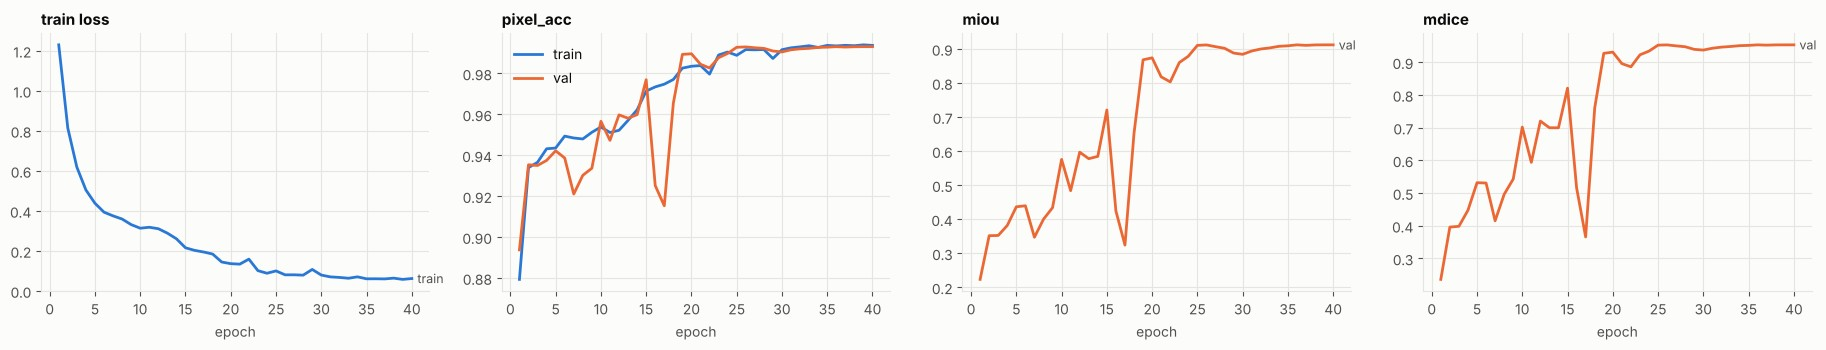

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.segmentation.evaluate import evaluate

metrics = evaluate(cfg)

mean IoU 0.945 | mean Dice 0.972 | pixel accuracy 0.995 (45 test images)
background           IoU 0.998   Dice 0.999
circle               IoU 0.953   Dice 0.976
square               IoU 0.917   Dice 0.957
triangle             IoU 0.914   Dice 0.955
reports -> outputs/segmentation_quick/reports


per_class_iou.png


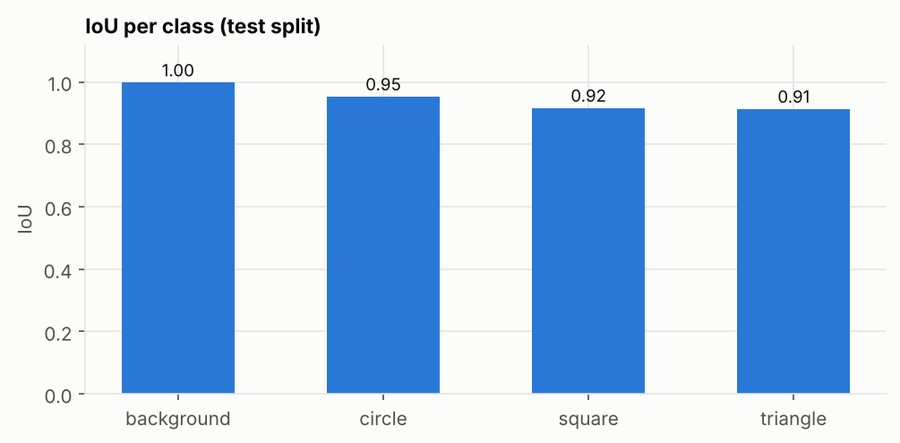

confusion_matrix.png


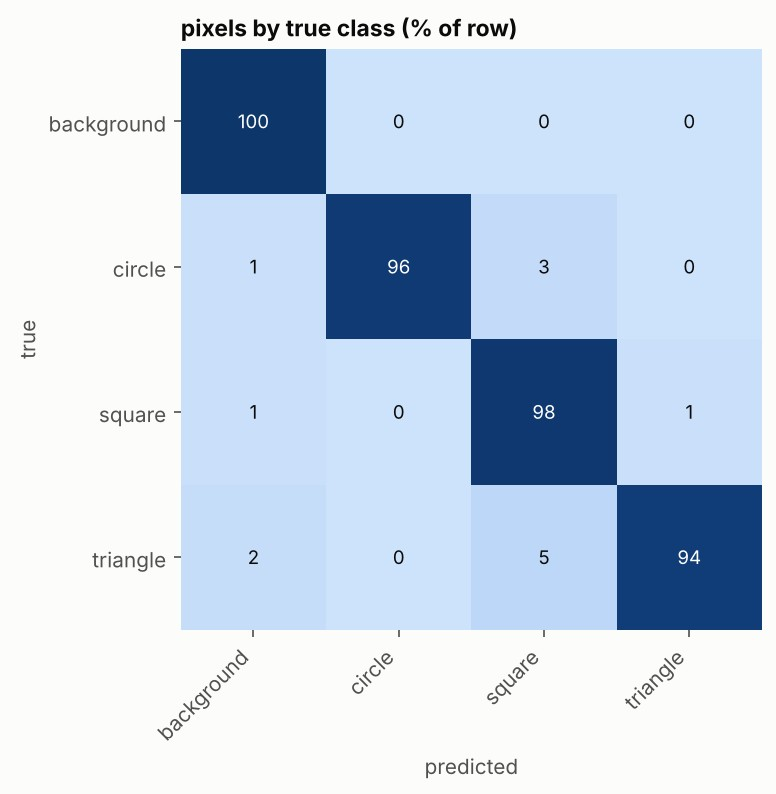

predictions.png


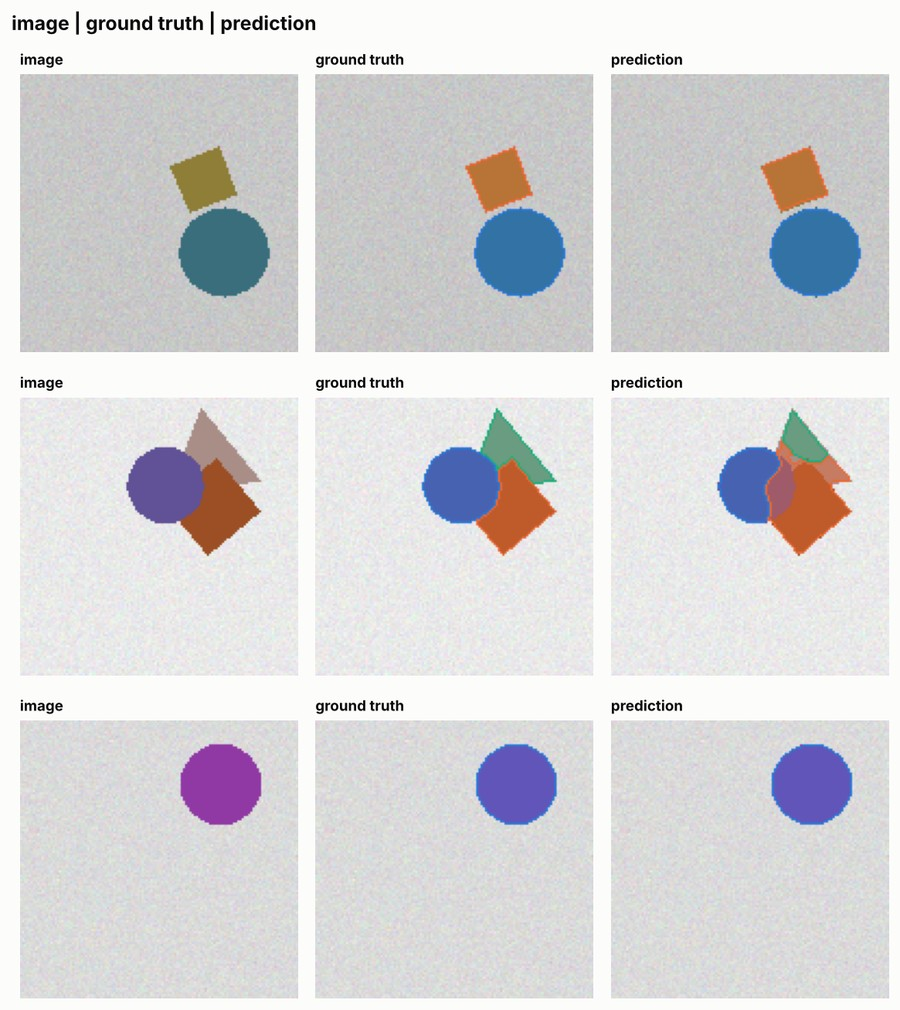

worst_images.png


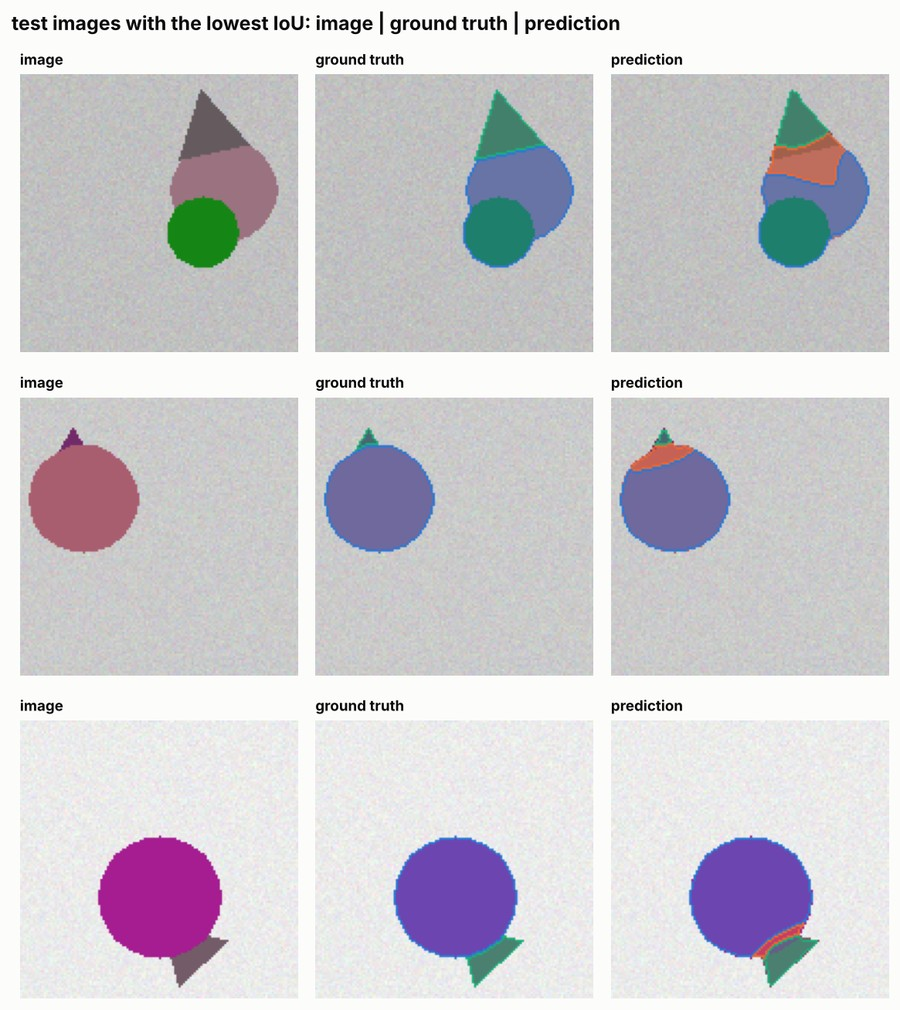

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['per_class_iou.png', 'confusion_matrix.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **IoU per class** — shared pixels ÷ pixels in either mask (1 = perfect outline). Look at the *worst* class, not the average.
* **Mean IoU (mIoU)** — IoU averaged over classes: the standard single number.
* **Dice** — a close relative of IoU (2·overlap ÷ total area of both); always ≥ IoU, same ordering.
* **Pixel accuracy** — share of pixels correct. *Misleading* when the background dominates: predicting "all background" can score 90%+. Quote it only next to mIoU.
* **Confusion matrix (pixels)** — each row shows where a true class's pixels went. Large off-diagonal cells show which classes bleed into each other (often object ↔ background at edges).
* **Worst images** — thin or tiny objects missed, ragged borders, a class painted on the wrong region. Ragged borders usually mean more resolution or training is needed.

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `train.dice_weight = 0` vs `1.0` — what does the Dice term do for the rarest class?
2. `model.arch = 'lraspp_mobilenet_v3_large'` — a lighter model; compare mIoU and time
3. `data.image_size = 192` — finer outlines, slower
4. `train.epochs` ×2 — is mIoU still rising?

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.